# 01 — จากคนที่นอนหลับ สู่สัญญาณ EEG และป้ายกำกับ

บทนี้ตอบคำถามพื้นฐาน: ข้อมูลมาจากอะไร, หนึ่งตัวอย่างยาวเท่าไร, และแต่ละ sleep stage มีจำนวนเท่าใด

เราจะแยกสองชุดให้ชัด:

- `data/sleep-edf/` — สำเนา local ขนาด 6 คน/12 records สำหรับเปิดดูเร็ว
- full cohort บนไดรฟ์ E — 78 คน/153 records/194,655 epochs ที่ preprocess และตรวจ parity แล้ว

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "paper_faithful").is_dir())
sys.path.insert(0, str(ROOT / "walkthrough"))

import matplotlib.pyplot as plt
import numpy as np
from walkthrough_lib import *

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
print(f"Project root : {PROJECT_ROOT}")
print(f"Bulk artifacts: {BULK_ROOT}")

Project root : C:\Users\Acer\OneDrive\Documents\เป้าๆรวยๆๆๆ\sleep_stage_reproduction
Bulk artifacts: E:\blp\sleep_stage_reproduction


## 1. จำนวนข้อมูลที่มีจริง

หนึ่ง `epoch` ในงาน sleep staging คือช่วงสัญญาณ 30 วินาที ไม่ใช่ training epoch

In [2]:
local = local_edf_inventory()
full = full_cohort_summary()

rows = [
    {"scope": "local files for demonstration", "subjects": local["subject_count"], "records": local["psg_files"], "epochs": "read on demand"},
    {"scope": "paper-faithful full cohort", "subjects": full["subjects"], "records": full["recordings"], "epochs": f"{full['epochs']:,}"},
]
print_records(rows, ["scope", "subjects", "records", "epochs"])
print("Local subject IDs:", ", ".join(local["subjects"]))
print("Full-cohort parity matches expected:", full["parity_matches_expected"])

scope                         | subjects | records | epochs        
------------------------------+----------+---------+---------------
local files for demonstration | 6        | 12      | read on demand
paper-faithful full cohort    | 78       | 153     | 194,655       
Local subject IDs: SC400, SC401, SC402, SC403, SC404, SC405
Full-cohort parity matches expected: True


## 2. ดูคลื่น Fpz–Cz จริง 30 วินาที

จุดวัด `Fpz–Cz` เป็นช่อง EEG เดียวตามบทความ เซลล์นี้อ่านเฉพาะ 3,000 samples (= 30 วินาที × 100 Hz) จาก EDF หนึ่งไฟล์

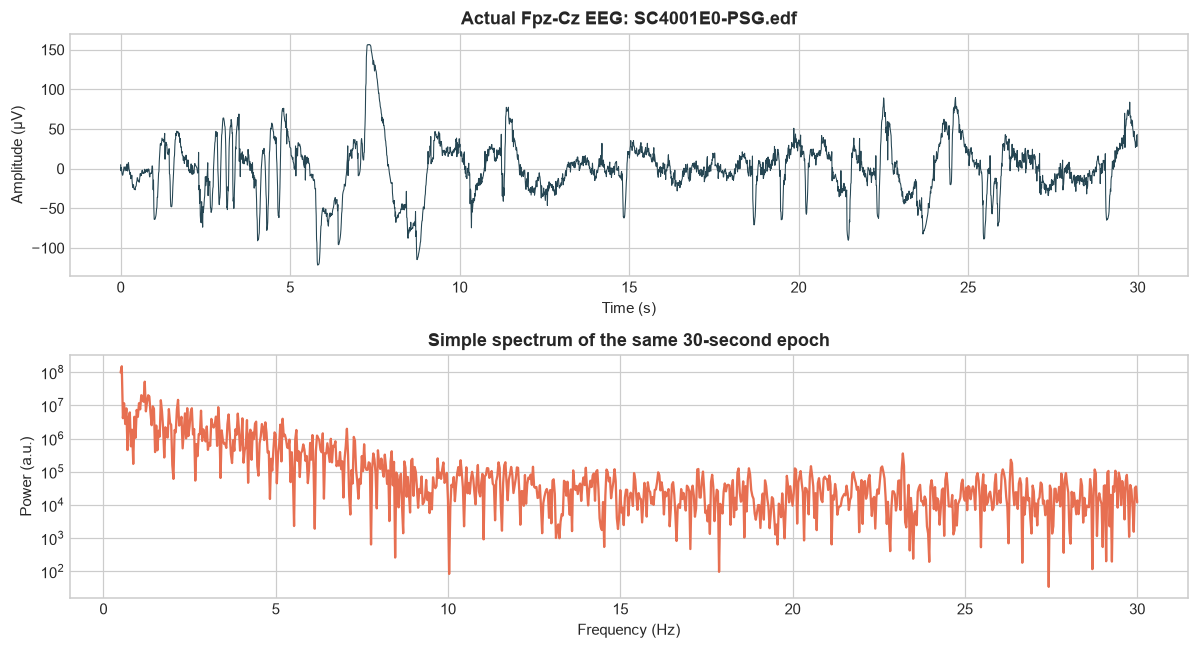

Sampling rate: 100 Hz | points shown: 3,000 | duration: 30 s


In [3]:
import mne

edf_path = sorted((PROJECT_ROOT / "data" / "sleep-edf").glob("*-PSG.edf"))[0]
raw = mne.io.read_raw_edf(edf_path, preload=False, verbose="ERROR")
sfreq = float(raw.info["sfreq"])
samples = int(30 * sfreq)
signal_uv = raw.get_data(picks=["EEG Fpz-Cz"], start=0, stop=samples)[0] * 1e6
time_s = np.arange(samples) / sfreq

fig, axes = plt.subplots(2, 1, figsize=(11, 6))
axes[0].plot(time_s, signal_uv, lw=0.7, color="#264653")
axes[0].set(title=f"Actual Fpz-Cz EEG: {edf_path.name}", xlabel="Time (s)", ylabel="Amplitude (µV)")

window = np.hanning(len(signal_uv))
freq = np.fft.rfftfreq(len(signal_uv), d=1/sfreq)
power = np.abs(np.fft.rfft((signal_uv - signal_uv.mean()) * window)) ** 2
mask = (freq >= 0.5) & (freq <= 30)
axes[1].semilogy(freq[mask], power[mask] + 1e-12, color="#e76f51")
axes[1].set(title="Simple spectrum of the same 30-second epoch", xlabel="Frequency (Hz)", ylabel="Power (a.u.)")
plt.tight_layout()
plt.show()

print(f"Sampling rate: {sfreq:.0f} Hz | points shown: {samples:,} | duration: {samples/sfreq:.0f} s")

## 3. การกระจายของ 5 sleep stages ใน full cohort

คลาสไม่ได้มีจำนวนเท่ากัน โดยเฉพาะ N1 และ N3 มีน้อยกว่า W/N2 มาก ความไม่สมดุลนี้เป็นสาเหตุหนึ่งที่ต้องรายงาน **macro-F1** ควบคู่ accuracy

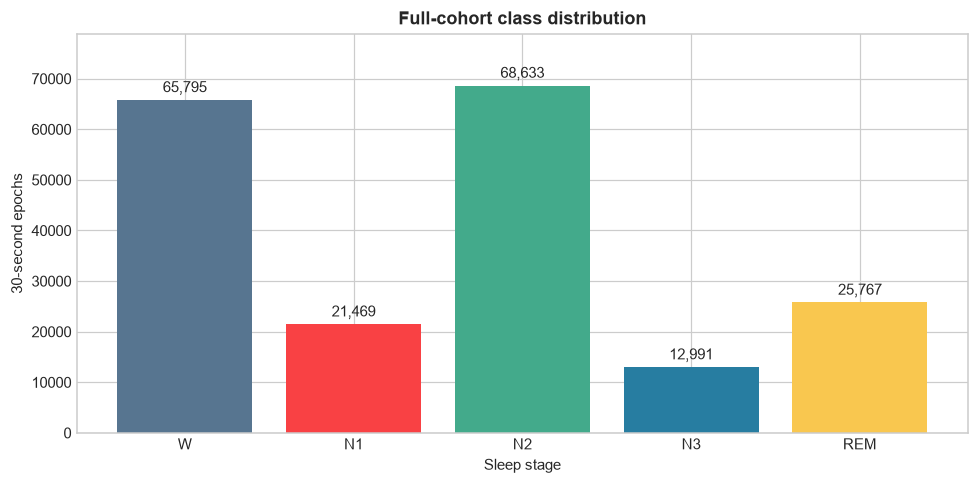

Label meaning: W=wake, N1=light sleep, N2=stable light sleep, N3=deep sleep, REM=rapid-eye-movement sleep


In [4]:
counts = full["class_counts"]
values = [counts[label] for label in LABELS]

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(LABELS, values, color=["#577590", "#f94144", "#43aa8b", "#277da1", "#f9c74f"])
ax.set(title="Full-cohort class distribution", xlabel="Sleep stage", ylabel="30-second epochs")
ax.bar_label(bars, labels=[f"{value:,}" for value in values], padding=3)
ax.set_ylim(0, max(values) * 1.15)
plt.tight_layout()
plt.show()

print("Label meaning: W=wake, N1=light sleep, N2=stable light sleep, N3=deep sleep, REM=rapid-eye-movement sleep")

## 4. สิ่งที่ preprocessing ทำ

1. เลือกช่อง `Fpz-Cz`
2. ใช้ sampling rate 100 Hz
3. แบ่งเป็นช่วงละ 30 วินาที (3,000 samples)
4. รวม stage 3 และ 4 แบบ R&K เป็น N3
5. ตัด movement/unknown และตัดช่วงตื่นไกลจากการนอนตามกติกา 30 นาที
6. บันทึก record, subject, hash และ class counts เพื่อ audit ย้อนกลับได้

บทถัดไปจะนำ epoch เหล่านี้ไปแปลงเป็นภาพเวลา–ความถี่แบบ SST